# PSI-159 + PSI-69: burn-time forecasting

This notebook estimates positive burn time from **pre-test** conditions. Primary results are source-specific because PSI-159 (burner) and PSI-69 (droplet) use different apparatuses; pooled results are comparison-only.

PSI-159 has operator-terminated (`FT`) observations, which may be right-censored. Its primary regression reference is therefore the `NATURAL_ONLY=True` model, evaluated with leave-one-base-fuel-out validation. A survival-analysis sensitivity model treats `SE` as observed natural extinction and `FT` as right-censored. PSI-69 keeps its grouped regression analysis; its termination semantics are not yet sufficient for survival modelling.

## Setup

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (average_precision_score, classification_report, mean_absolute_error,
                             median_absolute_error, root_mean_squared_error, roc_auc_score)
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from xgboost import XGBClassifier, XGBRegressor
except ImportError as exc:
    raise ImportError('Install the pinned dependencies first: `%pip install -r requirements-ml.txt`') from exc

SEED = 42
BOOTSTRAP_REPS = 2_000
sns.set_theme(style='whitegrid', context='notebook')

## 1. Ingest

Read the audited snapshot directly, preserving its provenance rather than relying on copied downloads.

In [2]:

from pathlib import Path
import pandas as pd
import numpy as np

PATHS = {
    'psi159_normal': Path('/kaggle/input/datasets/nhihhunhth/nasa-psi/691f7ea117f78b371b26f6fa.csv'),
    'psi159_inverse': Path('/kaggle/input/datasets/nhihhunhth/nasa-psi/691f7ea117f78b371b26f6fb.csv'),
    'psi69_flex': Path('/kaggle/input/datasets/nhihhunhth/nasa-psi/6792be99b7b6ff8e65037e3a.csv'),
}

# Check files
for name, path in PATHS.items():
    assert path.exists(), f'File not found: {path}'
    print(f'Found: {name}')

# Read and clean
def read_clean(path):
    frame = pd.read_csv(path, encoding='cp1252')
    frame.columns = frame.columns.str.strip()

    return frame.replace(
        r'^\s*([-–—])?\s*$',
        np.nan,
        regex=True
    )

# Load datasets
raw_159_normal = read_clean(PATHS['psi159_normal'])
raw_159_inverse = read_clean(PATHS['psi159_inverse'])
raw_69 = read_clean(PATHS['psi69_flex'])
pd.DataFrame({
    'source': ['PSI-159 normal', 'PSI-159 inverse', 'PSI-69 FLEX'],
    'rows': [len(raw_159_normal), len(raw_159_inverse), len(raw_69)],
    'columns': [raw_159_normal.shape[1], raw_159_inverse.shape[1], raw_69.shape[1]],
})

Found: psi159_normal
Found: psi159_inverse
Found: psi69_flex


,source,rows,columns
0,PSI-159 normal,179,18
1,PSI-159 inverse,1015,20
2,PSI-69 FLEX,274,15


## 2. Validation

Validation checks the expected schema, physically plausible fractions, and positive targets. Invalid values are made missing—not silently coerced to zero.

In [3]:
EXPECTED = {
    'PSI-159 normal': {'Fuel', 'Test', 'XO2 before test', 'approx p (bar)', 'burn time (sec)', 'Hot ignition'},
    'PSI-159 inverse': {'Fuel', 'Test', 'XO2', 'approx p (bar)', 'burn time (sec)', 'Hot ignition'},
    'PSI-69 FLEX': {'FLEX Test #', 'Fuel', 'Ambient pressure; mmHg', 'Burn time; s', 'Test end'},
}
for label, frame in [('PSI-159 normal', raw_159_normal), ('PSI-159 inverse', raw_159_inverse), ('PSI-69 FLEX', raw_69)]:
    missing = EXPECTED[label] - set(frame.columns)
    assert not missing, f'{label}: missing expected fields {missing}'
print('Schema checks passed.')

def audit_range(frame, column, low, high):
    values = pd.to_numeric(frame[column], errors='coerce')
    return pd.Series({'field': column, 'invalid': int(((values < low) | (values > high)).sum()),
                      'missing': int(values.isna().sum()), 'min': values.min(), 'max': values.max()})
pd.DataFrame([
    audit_range(raw_159_normal, 'XO2 before test', 0, 1),
    audit_range(raw_159_inverse, 'XO2', 0, 1),
    audit_range(raw_69, 'O initial ambient composition; mole fraction', 0, 1),
]).set_index('field')

Schema checks passed.


,invalid,missing,min,max
field,,,,
XO2 before test,0,0,0.179686,0.3997
XO2,0,861,0.120000,0.8500
O initial ambient composition; mole fraction,0,0,0.120000,0.3400


## 3. Duplicates and 4. Missing values

Exact duplicate rows are removed within their source. Missing predictors are imputed inside each cross-validation fold so validation data never influences training transforms.

In [4]:
raw_sources = {'PSI-159 normal': raw_159_normal, 'PSI-159 inverse': raw_159_inverse, 'PSI-69 FLEX': raw_69}
duplicate_report = pd.DataFrame([
    {'source': name, 'raw_rows': len(frame), 'exact_duplicates': int(frame.duplicated().sum()),
     'all_nan_rows': int(frame.isna().all(axis=1).sum())}
    for name, frame in raw_sources.items()
])
display(duplicate_report)
raw_159_normal = raw_159_normal.drop_duplicates().dropna(how='all').copy()
raw_159_inverse = raw_159_inverse.drop_duplicates().dropna(how='all').copy()
raw_69 = raw_69.drop_duplicates().dropna(how='all').copy()

# rebuild the dict AFTER cleaning, otherwise it still points at the old frames
raw_sources = {'PSI-159 normal': raw_159_normal, 'PSI-159 inverse': raw_159_inverse, 'PSI-69 FLEX': raw_69}
missing_report = pd.concat({n: f.isna().mean() for n, f in raw_sources.items()}, axis=1)
# NaN in this table = column does not exist in that source (not '0% missing')
missing_report[(missing_report.fillna(0) > 0).any(axis=1)].sort_values(list(missing_report.columns), ascending=False)

,source,raw_rows,exact_duplicates,all_nan_rows
0,PSI-159 normal,179,0,0
1,PSI-159 inverse,1015,860,861
2,PSI-69 FLEX,274,0,0


,PSI-159 normal,PSI-159 inverse,PSI-69 FLEX
Cool flame?,0.955307,NaN,NaN
Comments,0.754190,0.746753,NaN
Self-ext or flow term,0.256983,NaN,NaN
Peak burner T (C ),0.256983,NaN,NaN
burn time (sec),0.022346,0.000000,NaN
Color,NaN,0.220779,NaN
Self -ext or flow term,NaN,0.097403,NaN
Peak burner Temp (C),NaN,0.019481,NaN
Visible flame extinction diameter; mm,NaN,NaN,0.281022
Burning rate; mm,NaN,NaN,0.058394


In [5]:
import numpy as np, pandas as pd

# --- 159 normal ---
d = raw_159_normal.copy()
s = d['Cool flame?'].fillna('No').str.strip().str.lower()
d['cool_flame'] = s.str.startswith('yes').astype(int)
d['pci_type']   = s.str.extract(r'pci-(\w+)')[0].str.upper().fillna('none')
d['Cool flame?'] = d['Cool flame?'].fillna('No')
d['has_comment'] = d['Comments'].notna().astype(int)
d['Comments']    = d['Comments'].fillna('')
d['burn time (sec)'] = pd.to_numeric(d['burn time (sec)'], errors='coerce')
raw_159_normal = d.dropna(subset=['burn time (sec)']).copy()      # target: drop, không impute

# --- 159 inverse ---
d = raw_159_inverse.copy()
d['has_comment'] = d['Comments'].notna().astype(int)
d['Comments']    = d['Comments'].fillna('')
d['Color']       = d['Color'].fillna('Unknown')
for col in ['Peak burner Temp (C)', 'Peak burner temp (K)']:
    d[col] = pd.to_numeric(d[col], errors='coerce')               # '#VALUE!' -> NaN
d['Peak burner Temp (C)'] = d['Peak burner Temp (C)'].fillna(d['Peak burner temp (K)'] - 273.15)
d['Peak burner temp (K)'] = d['Peak burner temp (K)'].fillna(d['Peak burner Temp (C)'] + 273.15)
d['burn time (sec)'] = pd.to_numeric(d['burn time (sec)'], errors='coerce')
raw_159_inverse = d.dropna(subset=['burn time (sec)']).copy()

# --- 69 FLEX ---
d = raw_69.copy()
d['burn_time_approx'] = d['Burn time; s'].astype(str).str.contains('~').astype(int)
d['Burn time; s'] = d['Burn time; s'].astype(str).str.replace('~', '', regex=False)

num_cols = ['Burning rate; mm', 'Droplet initial diameter; mm',
            'Burn time; s', 'Visible flame extinction diameter; mm']
for c in num_cols:
    d[c] = pd.to_numeric(d[c], errors='coerce')                   # '–', 'nan' -> NaN

# cờ missing (giữ NaN, không impute các cột đo sau test)
d['ext_diam_missing']     = d['Visible flame extinction diameter; mm'].isna().astype(int)
d['burning_rate_missing'] = d['Burning rate; mm'].isna().astype(int)
d['droplet_d0_missing']   = d['Droplet initial diameter; mm'].isna().astype(int)
# Droplet initial diameter là feature -> impute trong pipeline sau khi split

raw_69 = d.dropna(subset=['Burn time; s']).copy()                 # target: drop

# kiểm tra lại
for n, f in {'normal': raw_159_normal, 'inverse': raw_159_inverse, 'flex': raw_69}.items():
    print(n, len(f), f.isna().sum()[lambda s: s > 0].to_dict())

normal 175 {'Self-ext or flow term': 42, 'Peak burner T (C )': 42}
inverse 154 {'Self -ext or flow term': 15, 'Peak burner Temp (C)': 2, 'Peak burner temp (K)': 2}
flex 268 {'Droplet initial diameter; mm': 8, 'Visible flame extinction diameter; mm': 72, 'Burning rate; mm': 11}


## 5. Feature engineering

Only pre-test conditions are features. All post-test observations—after-test composition, observed burn rate, extinction diameter, peak temperature, comments and raw termination text—are excluded to prevent target leakage.

In [6]:
CANONICAL_FEATURES = [
    'source_study', 'flame_type', 'fuel', 'pressure_bar', 'o2_fraction', 'n2_fraction',
    'co_fraction', 'he_fraction', 'fuel_fraction', 'hc_flow_mg_s', 'o2_flow_mg_s',
    'initial_droplet_diameter_mm', 'tad_k', 'zst',
]


def numeric(frame, column):
    """Coerce numeric text while preserving invalid measurements as missing."""
    col = frame.get(column, pd.Series(np.nan, index=frame.index))
    col = col.astype('string').str.replace('~', '', regex=False).str.strip()
    return pd.to_numeric(col, errors='coerce')


def canonical_159(frame, flame_type):
    before_fuel = 'Xf before test' if flame_type == 'Inverse' else 'Xf'
    o2 = 'XO2' if flame_type == 'Inverse' else 'XO2 before test'
    hc = 'HC burnrate (mg/s)' if flame_type == 'Inverse' else 'mHC (mg/s)'
    o2_flow = 'O2 flow rate (mg/s)' if flame_type == 'Inverse' else None
    term_col = 'Self -ext or flow term' if flame_type == 'Inverse' else 'Self-ext or flow term'
    term = frame[term_col].astype('string').str.strip().str.upper()
    hot = frame['Hot ignition'].astype('string').str.strip().str.lower()
    burn_raw = frame['burn time (sec)'].astype('string')
    burn = numeric(frame, 'burn time (sec)')

    # A recorded termination is evidence that ignition occurred. This retains PSI-159 test 21106 F4.
    ignited = (hot.isin(['yes', 'flash']) | term.notna()).astype('int8')
    natural = pd.Series(pd.NA, index=frame.index, dtype='Int8')
    natural.loc[term.notna()] = term.loc[term.notna()].eq('SE').astype('int8')
    termination_mode = term.map({'SE': 'natural', 'FT': 'forced'}).astype('string')

    return pd.DataFrame({
        'source_study': 'PSI-159', 'flame_type': flame_type,
        'fuel': frame['Fuel'].astype('string').str.lower().str.strip(),
        'pressure_bar': numeric(frame, 'approx p (bar)'), 'o2_fraction': numeric(frame, o2),
        'n2_fraction': np.nan, 'co_fraction': np.nan, 'he_fraction': np.nan,
        'fuel_fraction': numeric(frame, before_fuel), 'hc_flow_mg_s': numeric(frame, hc),
        'o2_flow_mg_s': numeric(frame, o2_flow) if o2_flow else np.nan,
        'initial_droplet_diameter_mm': np.nan, 'tad_k': numeric(frame, 'Tad (K)'),
        'zst': numeric(frame, 'Zst'), 'burn_time_s': burn,
        'ignited': ignited,
        'flash': (hot.eq('flash') | burn.eq(1)).fillna(False).astype('int8'),
        'natural_extinction': natural, 'termination_mode': termination_mode,
        'test_id': frame['Test'].astype('string'),
        'session': '159|' + flame_type + '|' + frame['Day'].astype('string').fillna('unknown'),
        'burn_time_approx': burn_raw.str.contains('~', regex=False).fillna(False).astype('int8'),
    })


def canonical_69(frame):
    end = frame['Test end'].astype('string').str.strip().str.lower()
    burn = numeric(frame, 'Burn time; s')
    natural = pd.Series(pd.NA, index=frame.index, dtype='Int8')
    natural.loc[end.isin(['extinction', 'disruption'])] = end.loc[end.isin(['extinction', 'disruption'])].eq('extinction').astype('int8')
    termination_mode = end.map({'extinction': 'natural', 'disruption': 'forced'}).astype('string')
    return pd.DataFrame({
        'source_study': 'PSI-69', 'flame_type': 'Droplet',
        'fuel': frame['Fuel'].astype('string').str.lower().str.strip(),
        'pressure_bar': numeric(frame, 'Ambient pressure; mmHg') * 1.333223684e-3,
        'o2_fraction': numeric(frame, 'O initial ambient composition; mole fraction'),
        'n2_fraction': numeric(frame, 'N initial ambient composition; mole fraction'),
        'co_fraction': numeric(frame, 'CO initial ambient composition; mole fraction'),
        'he_fraction': numeric(frame, 'He initial ambient composition; mole fraction'),
        'fuel_fraction': np.nan, 'hc_flow_mg_s': np.nan, 'o2_flow_mg_s': np.nan,
        'initial_droplet_diameter_mm': numeric(frame, 'Droplet initial diameter; mm'),
        'tad_k': np.nan, 'zst': np.nan, 'burn_time_s': burn,
        'ignited': burn.gt(0).fillna(False).astype('int8'), 'flash': 0,
        # Completion is intentionally unknown, not class 0.
        'natural_extinction': natural, 'termination_mode': termination_mode,
        'test_id': frame['FLEX Test #'].astype('string'),
        # FLEX Identifier is almost unique per row; Test Date is the defensible group.
        'session': '69|' + frame['Test Date'].astype('string').fillna('unknown'),
        'burn_time_approx': frame['Burn time; s'].astype('string').str.contains('~', regex=False).fillna(False).astype('int8'),
    })


df = pd.concat([
    canonical_159(raw_159_normal, 'Normal'),
    canonical_159(raw_159_inverse, 'Inverse'),
    canonical_69(raw_69),
], ignore_index=True)

for col in ['o2_fraction', 'n2_fraction', 'co_fraction', 'he_fraction', 'fuel_fraction']:
    df.loc[~df[col].between(0, 1), col] = np.nan
for col in ['pressure_bar', 'hc_flow_mg_s', 'o2_flow_mg_s', 'initial_droplet_diameter_mm', 'tad_k', 'zst', 'burn_time_s']:
    df.loc[df[col] < 0, col] = np.nan

# Legacy derived features remain only for the explicitly labelled full-feature ablation.
df['inert_fraction'] = df[['n2_fraction', 'co_fraction', 'he_fraction']].sum(axis=1, min_count=1)
df['composition_sum'] = df[['o2_fraction', 'inert_fraction']].sum(axis=1, min_count=1)
df['o2_to_inert_ratio'] = df['o2_fraction'] / df['inert_fraction'].replace(0, np.nan)
df['base_fuel'] = df['fuel'].str.replace(r'^\s*\d+(?:\.\d+)?\s*%\s*', '', regex=True).str.strip()

FEATURES_FULL = CANONICAL_FEATURES + ['inert_fraction', 'composition_sum', 'o2_to_inert_ratio']
FEATURES_CLEAN = [f for f in FEATURES_FULL if f not in [
    'composition_sum', 'inert_fraction', 'o2_to_inert_ratio', 'o2_flow_mg_s',
]]
FEATURES_CLEAN_NO_HC = [f for f in FEATURES_CLEAN if f != 'hc_flow_mg_s']
FEATURE_SETS = {
    'full_legacy': FEATURES_FULL,
    'clean': FEATURES_CLEAN,
    'clean_no_hc_flow': FEATURES_CLEAN_NO_HC,
}

print('Termination labels and ignitions:')
display(df.groupby(['source_study', 'termination_mode'], dropna=False).agg(
    rows=('test_id', 'size'), ignited=('ignited', 'sum'), burn_time_missing=('burn_time_s', lambda s: s.isna().sum())
))
print('PSI-69 test-date groups:', df.loc[df.source_study.eq('PSI-69'), 'session'].nunique())

Termination labels and ignitions:


rows  ignited  burn_time_missing
source_study termination_mode                                  
PSI-159      forced              89       89                0.0
             natural            183      183                0.0
             <NA>                57        0                0.0
PSI-69       forced              57       57                0.0
             natural            184      184                0.0
             <NA>                27       27                0.0

PSI-69 test-date groups: 80


## 6. EDA

count  median       mean   min    max
source_study fuel                                              
PSI-69       methanol       156    11.9  13.510449   0.3   39.2
             heptane        112     7.5   7.938214  0.55   24.0
PSI-159      ethane          67    35.0  36.529851   0.0  136.0
             propane         63    12.0  29.460317   0.0  259.0
             butane          58     9.0   26.62931   0.0  107.0
             30% butane      52    27.0  46.288462   0.0  251.0
             30% propane     36     5.0  18.472222   0.0  147.0
             30% ethane      27    51.0  90.333333   0.0  304.0
             50% butane      26    20.0  31.269231   0.0  120.0

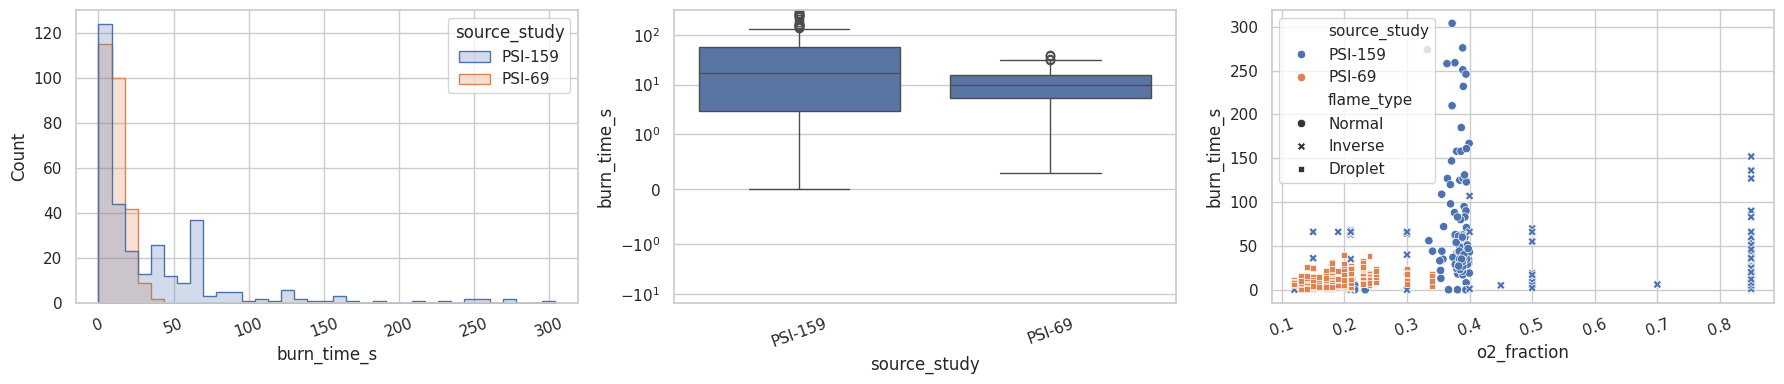

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(data=df, x='burn_time_s', hue='source_study', bins=35, element='step', ax=axes[0])
sns.boxplot(data=df, x='source_study', y='burn_time_s', ax=axes[1])
axes[1].set_yscale('symlog', linthresh=1)
sns.scatterplot(data=df, x='o2_fraction', y='burn_time_s', hue='source_study', style='flame_type', ax=axes[2])
for ax in axes: ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
display(df.groupby(['source_study', 'fuel'])['burn_time_s'].agg(['count', 'median', 'mean', 'min', 'max']).sort_values('count', ascending=False))

In [8]:
zero = df['burn_time_s'].eq(0)
print('Zero burn times per study:')
display(df.groupby('source_study')['burn_time_s'].agg(rows='size', zeros=lambda s: int((s == 0).sum())))
print('Ignition rule audit (a termination now counts as ignition in PSI-159):')
display(df.groupby(['source_study', 'ignited', 'termination_mode'], dropna=False).size().rename('n'))
print('Approximate burn times (~):', int(df['burn_time_approx'].sum()))

Zero burn times per study:


,rows,zeros
source_study,,
PSI-159,329,57.0
PSI-69,268,0.0


Ignition rule audit (a termination now counts as ignition in PSI-159):


source_study  ignited  termination_mode
PSI-159       0        <NA>                 57
              1        forced               89
                       natural             183
PSI-69        1        forced               57
                       natural             184
                       <NA>                 27
Name: n, dtype: int64

Approximate burn times (~): 0


In [9]:
# Verify the previously lost PSI-159 record and show the raw combinations behind the new label.
psi159_label_audit = df.loc[df['source_study'].eq('PSI-159'),
                            ['test_id', 'fuel', 'ignited', 'burn_time_s', 'termination_mode']]
display(psi159_label_audit[psi159_label_audit['test_id'].astype('string').str.contains('21106', na=False)])
display(pd.crosstab(df.loc[df.source_study.eq('PSI-159'), 'ignited'],
                    df.loc[df.source_study.eq('PSI-159'), 'termination_mode'].fillna('unknown')))

,test_id,fuel,ignited,burn_time_s,termination_mode
30,21106A4,50% butane,1,60.0,natural
31,21106 B1,50% butane,1,62.0,natural
32,21106 C1,50% butane,1,63.0,natural
33,21106 D1,50% butane,1,120.0,natural
34,21106 F1,50% butane,1,72.0,forced
35,21106 F3,50% butane,1,13.0,forced
36,21106 F4,50% butane,1,22.0,forced
37,21106 G6,50% butane,1,20.0,natural
38,21106 G7,50% butane,1,20.0,natural
39,21106 G9,50% butane,1,14.0,natural


termination_mode,forced,natural,unknown
ignited,,,
0,0,0,57
1,89,183,0


In [10]:
# Compare observed times before modelling. A systematically shorter forced group supports the censoring concern.
termination_time_summary = (
    df.loc[df['ignited'].eq(1) & df['burn_time_s'].gt(0) & df['termination_mode'].notna()]
      .groupby(['source_study', 'termination_mode'])['burn_time_s']
      .agg(n='size', median='median', mean='mean', std='std', min='min', max='max')
)
display(termination_time_summary)

n  median       mean        std   min    max
source_study termination_mode                                                
PSI-159      forced             89    66.0  70.494382  51.476412  12.0  276.0
             natural           183    13.0  32.229508   50.68741   0.5  304.0
PSI-69       forced             57    14.1  13.808772   6.606957   1.7   30.7
             natural           184    8.65  10.257663   7.638112   0.3   39.2

The `Completion` and missing `Test end` labels in PSI-69 are intentionally **not** converted to non-natural extinction. They remain unknown and are excluded from the classifier. They are retained in `NATURAL_ONLY=False` regression because the burn time itself is observed; use the `NATURAL_ONLY=True` results when restricting to known natural extinctions.

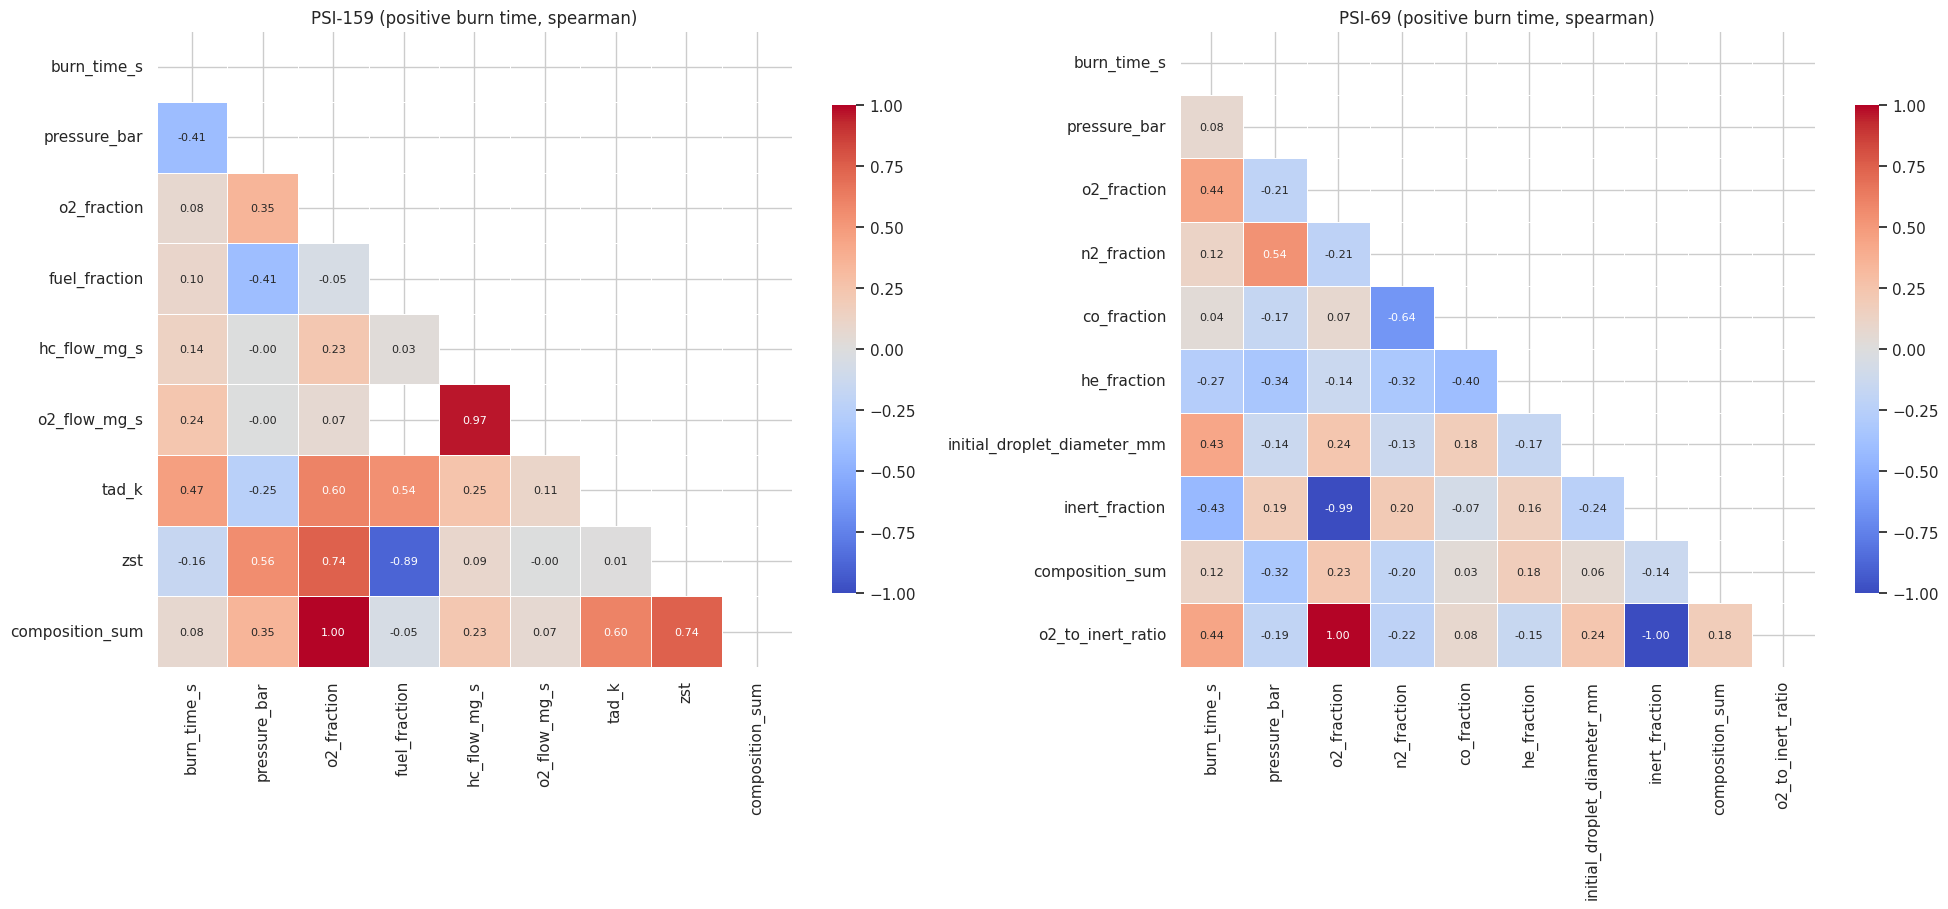

In [11]:
num_cols = ['burn_time_s', 'pressure_bar', 'o2_fraction', 'n2_fraction', 'co_fraction', 'he_fraction',
            'fuel_fraction', 'hc_flow_mg_s', 'o2_flow_mg_s', 'initial_droplet_diameter_mm',
            'tad_k', 'zst', 'inert_fraction', 'composition_sum', 'o2_to_inert_ratio']

def corr_heatmap(data, title, ax, method='spearman'):
    d = data.loc[data['burn_time_s'].gt(0), num_cols].astype(float)
    d = d.dropna(axis=1, how='all')
    d = d.loc[:, d.nunique(dropna=True) > 1]
    corr = d.corr(method=method, min_periods=10)
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
                square=True, linewidths=0.5, cbar_kws={'shrink': 0.7}, annot_kws={'size': 8}, ax=ax)
    ax.set_title(f'{title} (positive burn time, {method})')

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
corr_heatmap(df[df['source_study'] == 'PSI-159'], 'PSI-159', axes[0])
corr_heatmap(df[df['source_study'] == 'PSI-69'], 'PSI-69', axes[1])
plt.tight_layout()

## 7. Source-specific grouped evaluation

PSI-159 uses explicit leave-one-`base_fuel`-out validation: each fold withholds an entire fuel group. PSI-69 remains grouped by `Test Date`. The pooled run is a sensitivity comparison only, not a production-model selection step.

In [12]:
EXCLUDE_FLASH = True
PRIMARY_NATURAL_ONLY = True
# The all-eligible model is retained only as a sensitivity result for the censoring assumption.
NATURAL_ONLY_VALUES = (PRIMARY_NATURAL_ONLY, False)


def regression_rows(data, natural_only):
    keep = data['burn_time_s'].gt(0) & data['ignited'].eq(1)
    if EXCLUDE_FLASH:
        keep &= ~data['flash'].eq(1)
    if natural_only:
        keep &= data['natural_extinction'].eq(1)
    return data.loc[keep].copy()


def survival_rows(data):
    """PSI-159 rows with an unambiguous event (SE) or right-censoring point (FT)."""
    rows = regression_rows(data, natural_only=False)
    rows = rows.loc[rows['source_study'].eq('PSI-159') & rows['termination_mode'].isin(['natural', 'forced'])].copy()
    rows['event_observed'] = rows['termination_mode'].eq('natural').astype('int8')
    return rows


def groups_for(data, scope):
    if scope == 'PSI-159':
        return data['base_fuel'].fillna('unknown_fuel')
    if scope == 'PSI-69':
        return data['session'].fillna('unknown_test_date')
    return np.where(data['source_study'].eq('PSI-159'),
                    '159|' + data['base_fuel'].fillna('unknown_fuel'),
                    '69|' + data['session'].fillna('unknown_test_date'))


def grouped_splitter(scope, groups):
    if scope == 'PSI-159':
        return LeaveOneGroupOut(), 'LeaveOneGroupOut(base_fuel)'
    return GroupKFold(n_splits=min(5, groups.nunique())), 'GroupKFold(Test Date)'


def usable_features(data, requested, scope):
    features = [f for f in requested if f in data.columns]
    if scope != 'pooled':
        features = [f for f in features if f != 'source_study']
    return [f for f in features if data[f].notna().any()]


for natural_only in NATURAL_ONLY_VALUES:
    rows = regression_rows(df, natural_only)
    role = 'PRIMARY regression reference' if natural_only == PRIMARY_NATURAL_ONLY else 'censoring sensitivity'
    print(f'{role} | NATURAL_ONLY={natural_only}: {len(rows)} regression rows')
    display(rows.groupby('source_study').agg(rows=('test_id', 'size'),
                                             known_natural=('natural_extinction', lambda s: int(s.eq(1).sum())),
                                             known_forced=('natural_extinction', lambda s: int(s.eq(0).sum()))))

PRIMARY regression reference | NATURAL_ONLY=True: 345 regression rows


,rows,known_natural,known_forced
source_study,,,
PSI-159,161,161,0
PSI-69,184,184,0


censoring sensitivity | NATURAL_ONLY=False: 518 regression rows


,rows,known_natural,known_forced
source_study,,,
PSI-159,250,161,89
PSI-69,268,184,57


## 8. Models and metric helpers

Missing values are imputed inside each fold with medians **without missingness indicators**. This prevents source-identifying absence patterns from entering a pooled model. Ridge is included beside tree models because each source has only roughly 250 rows.

In [13]:
class FuelMedianBaseline(BaseEstimator, RegressorMixin):
    """Training-fold median by base fuel; unseen fuel receives the global median."""
    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        self.global_ = float(np.median(y))
        self.by_fuel_ = pd.Series(y).groupby(X['fuel'].fillna('unknown_fuel').to_numpy()).median().to_dict()
        return self

    def predict(self, X):
        return X['fuel'].fillna('unknown_fuel').map(self.by_fuel_).fillna(self.global_).to_numpy(dtype=float)


def make_preprocessor(X):
    numeric_features = X.select_dtypes(include='number').columns.tolist()
    categorical_features = X.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median', add_indicator=False)),
            ('scale', StandardScaler()),
        ]), numeric_features),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore')),
        ]), categorical_features),
    ], verbose_feature_names_out=False)


REGRESSORS = {
    'baseline_global_median': DummyRegressor(strategy='median'),
    'baseline_fuel_median': FuelMedianBaseline(),
    'ridge': Ridge(alpha=10.0),
    'random_forest': RandomForestRegressor(n_estimators=500, min_samples_leaf=3, max_features=0.8,
                                           random_state=SEED, n_jobs=-1),
    'extra_trees': ExtraTreesRegressor(n_estimators=500, min_samples_leaf=2, max_features=0.9,
                                       random_state=SEED, n_jobs=-1),
    'xgboost': XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.03, subsample=0.8,
                            colsample_bytree=0.8, objective='reg:squarederror', random_state=SEED, n_jobs=-1),
}
def predict_with_interval(model, X_new, interval):
    prediction = np.asarray(model.predict(X_new), dtype=float)
    radius = interval['half_width_s']
    coverage_pct = int(round(interval['coverage'] * 100))

    return pd.DataFrame({
        'prediction_s': prediction,
        f'lower_{coverage_pct}_s': np.maximum(0, prediction - radius),
        f'upper_{coverage_pct}_s': prediction + radius,
    }, index=X_new.index)

def make_model(name, X):
    estimator = REGRESSORS[name]
    inner = estimator if name.startswith('baseline') else Pipeline([
        ('preprocessor', make_preprocessor(X)), ('model', estimator),
    ])
    return TransformedTargetRegressor(regressor=inner, func=np.log1p, inverse_func=np.expm1)

def conformal_half_width(y_true, y_pred, coverage=0.90):
    """Distribution-free prediction-interval radius from OOF residuals."""
    residuals = np.abs(np.asarray(y_true) - np.asarray(y_pred))
    rank = min(len(residuals), int(np.ceil((len(residuals) + 1) * coverage)))
    return float(np.partition(residuals, rank - 1)[rank - 1])
    
def bootstrap_interval(y_true, y_pred, metric=mean_absolute_error, reps=BOOTSTRAP_REPS):
    rng = np.random.default_rng(SEED)
    indices = rng.integers(0, len(y_true), size=(reps, len(y_true)))
    values = np.array([metric(y_true[idx], y_pred[idx]) for idx in indices])
    return np.quantile(values, [0.025, 0.975])

## 9. Cross-validation and feature ablation

PSI-159's `NATURAL_ONLY=True` clean regression is the primary reference. `NATURAL_ONLY=False` is displayed only to show sensitivity to the censoring decision. Every PSI-159 fold is explicit leave-one-base-fuel-out; all metrics must therefore be read as estimates over only three held-out fuel groups.

In [14]:
def evaluate_models(data, scope, feature_set_name, model_names, natural_only):
    reg = regression_rows(data, natural_only)
    if scope != 'pooled':
        reg = reg.loc[reg['source_study'].eq(scope)].copy()
    features = usable_features(reg, FEATURE_SETS[feature_set_name], scope)
    groups = pd.Series(groups_for(reg, scope), index=reg.index, dtype='string')
    if groups.nunique() < 3:
        print(f'Skipped {scope}, NATURAL_ONLY={natural_only}: only {groups.nunique()} groups.')
        return None

    X, y = reg[features].copy(), reg['burn_time_s'].to_numpy(dtype=float)
    cv, split_strategy = grouped_splitter(scope, groups)
    fold_ids = list(cv.split(X, y, groups))
    predictions = {name: np.full(len(reg), np.nan) for name in model_names}
    fold_rows = []

    for fold, (tr, te) in enumerate(fold_ids, start=1):
        baseline = make_model('baseline_global_median', X.iloc[tr]).fit(X.iloc[tr], y[tr])
        baseline_pred = baseline.predict(X.iloc[te])
        for name in model_names:
            model = make_model(name, X.iloc[tr]).fit(X.iloc[tr], y[tr])
            pred = model.predict(X.iloc[te])
            predictions[name][te] = pred
            fold_rows.append({
                'scope': scope, 'natural_only': natural_only, 'feature_set': feature_set_name,
                'split_strategy': split_strategy, 'model': name, 'fold': fold, 'n_test': len(te),
                'MAE_s': mean_absolute_error(y[te], pred),
                'MedAE_s': median_absolute_error(y[te], pred),
                'RMSE_s': root_mean_squared_error(y[te], pred),
                'MAE_delta_vs_global_baseline_s': mean_absolute_error(y[te], pred) - mean_absolute_error(y[te], baseline_pred),
            })

    fold_metrics = pd.DataFrame(fold_rows)
    summary = (fold_metrics.groupby(['scope', 'natural_only', 'feature_set', 'split_strategy', 'model'], as_index=False)
                .agg(**{'CV MAE (s)': ('MAE_s', 'mean'), 'CV MAE std (s)': ('MAE_s', 'std'),
                        'CV MedAE (s)': ('MedAE_s', 'mean'), 'CV MedAE std (s)': ('MedAE_s', 'std'),
                        'Delta MAE vs baseline (s)': ('MAE_delta_vs_global_baseline_s', 'mean')}))
    oof = reg[['source_study', 'flame_type', 'fuel', 'base_fuel', 'session', 'burn_time_s']].reset_index(drop=True).copy()
    for name, pred in predictions.items():
        oof[name] = pred
    return {'scope': scope, 'natural_only': natural_only, 'features': features, 'groups': groups,
            'split_strategy': split_strategy, 'fold_metrics': fold_metrics, 'summary': summary, 'oof': oof}


primary_runs, ablation_runs, best_models = [], [], {}
candidate_models = ['baseline_global_median', 'baseline_fuel_median', 'ridge', 'random_forest', 'extra_trees', 'xgboost']
for natural_only in NATURAL_ONLY_VALUES:
    for source in ['PSI-159', 'PSI-69']:
        primary = evaluate_models(df, source, 'clean', candidate_models, natural_only)
        if primary is None:
            continue
        primary_runs.append(primary)
        label = 'PRIMARY regression reference' if natural_only == PRIMARY_NATURAL_ONLY else 'censoring sensitivity'
        print(f'{source} | {label}')
        display(primary['summary'].sort_values('CV MAE (s)'))
        non_baseline = primary['summary'].loc[~primary['summary']['model'].str.startswith('baseline')]
        champion_name = non_baseline.sort_values('CV MAE (s)').iloc[0]['model']
        best_models[(source, natural_only)] = champion_name

        for feature_set_name in FEATURE_SETS:
            ablation = evaluate_models(df, source, feature_set_name,
                                       ['baseline_global_median', champion_name], natural_only)
            if ablation is not None:
                ablation_runs.append(ablation)

primary_summary = pd.concat([run['summary'] for run in primary_runs], ignore_index=True)
ablation_summary = pd.concat([run['summary'] for run in ablation_runs], ignore_index=True)
print('Source-specific model comparison:')
display(primary_summary.sort_values(['scope', 'natural_only', 'CV MAE (s)']))
print('Feature ablation using the selected source-specific model:')
display(ablation_summary.loc[~ablation_summary.model.str.startswith('baseline')].sort_values(
    ['scope', 'natural_only', 'CV MAE (s)']))

pooled_comparison = evaluate_models(df, 'pooled', 'clean', candidate_models, natural_only=False)
if pooled_comparison is not None:
    print('Pooled comparison only (not a primary result):')
    display(pooled_comparison['summary'].sort_values('CV MAE (s)'))

PSI-159 | PRIMARY regression reference


,scope,natural_only,feature_set,split_strategy,model,CV MAE (s),CV MAE std (s),CV MedAE (s),CV MedAE std (s),Delta MAE vs baseline (s)
5,PSI-159,True,clean,LeaveOneGroupOut(base_fuel),xgboost,19.778087,10.658913,8.785873,3.158035,-10.103023
2,PSI-159,True,clean,LeaveOneGroupOut(base_fuel),extra_trees,20.481612,4.616228,9.937069,1.102075,-9.399498
3,PSI-159,True,clean,LeaveOneGroupOut(base_fuel),random_forest,21.146395,9.226924,8.776254,3.270355,-8.734715
4,PSI-159,True,clean,LeaveOneGroupOut(base_fuel),ridge,22.178436,8.245019,9.868511,3.564360,-7.702674
0,PSI-159,True,clean,LeaveOneGroupOut(base_fuel),baseline_fuel_median,29.881111,9.484478,14.638840,1.519154,0.000000
1,PSI-159,True,clean,LeaveOneGroupOut(base_fuel),baseline_global_median,29.881111,9.484478,14.638840,1.519154,0.000000


PSI-69 | PRIMARY regression reference


,scope,natural_only,feature_set,split_strategy,model,CV MAE (s),CV MAE std (s),CV MedAE (s),CV MedAE std (s),Delta MAE vs baseline (s)
2,PSI-69,True,clean,GroupKFold(Test Date),extra_trees,2.772316,0.667791,1.877275,0.674033,-2.926587
5,PSI-69,True,clean,GroupKFold(Test Date),xgboost,3.065837,0.656210,2.182119,0.820354,-2.633065
3,PSI-69,True,clean,GroupKFold(Test Date),random_forest,3.177352,0.814077,2.148120,0.871846,-2.521551
4,PSI-69,True,clean,GroupKFold(Test Date),ridge,4.204179,0.812879,2.672673,0.563251,-1.494723
0,PSI-69,True,clean,GroupKFold(Test Date),baseline_fuel_median,5.023124,1.299732,4.080383,1.823247,-0.675778
1,PSI-69,True,clean,GroupKFold(Test Date),baseline_global_median,5.698902,0.957666,4.360000,1.040673,0.000000


PSI-159 | censoring sensitivity


,scope,natural_only,feature_set,split_strategy,model,CV MAE (s),CV MAE std (s),CV MedAE (s),CV MedAE std (s),Delta MAE vs baseline (s)
3,PSI-159,False,clean,LeaveOneGroupOut(base_fuel),random_forest,27.555810,5.953230,15.312303,2.056986,-9.699427
5,PSI-159,False,clean,LeaveOneGroupOut(base_fuel),xgboost,27.577484,7.136247,13.794387,3.652956,-9.677754
2,PSI-159,False,clean,LeaveOneGroupOut(base_fuel),extra_trees,28.714435,7.034193,16.107440,3.542846,-8.540802
4,PSI-159,False,clean,LeaveOneGroupOut(base_fuel),ridge,32.538573,5.507613,18.583691,2.116362,-4.716665
0,PSI-159,False,clean,LeaveOneGroupOut(base_fuel),baseline_fuel_median,37.255238,5.041771,26.000000,2.645751,0.000000
1,PSI-159,False,clean,LeaveOneGroupOut(base_fuel),baseline_global_median,37.255238,5.041771,26.000000,2.645751,0.000000


... (4 outputs left out)

Feature ablation using the selected source-specific model:


,scope,natural_only,feature_set,split_strategy,model,CV MAE (s),CV MAE std (s),CV MedAE (s),CV MedAE std (s),Delta MAE vs baseline (s)
13,PSI-159,False,full_legacy,LeaveOneGroupOut(base_fuel),random_forest,27.533233,5.898740,14.953082,1.687087,-9.722005
15,PSI-159,False,clean,LeaveOneGroupOut(base_fuel),random_forest,27.555810,5.953230,15.312303,2.056986,-9.699427
17,PSI-159,False,clean_no_hc_flow,LeaveOneGroupOut(base_fuel),random_forest,29.305500,5.357747,15.645190,2.590446,-7.949737
1,PSI-159,True,full_legacy,LeaveOneGroupOut(base_fuel),xgboost,19.621067,10.675029,9.661084,3.704451,-10.260044
3,PSI-159,True,clean,LeaveOneGroupOut(base_fuel),xgboost,19.778087,10.658913,8.785873,3.158035,-10.103023
5,PSI-159,True,clean_no_hc_flow,LeaveOneGroupOut(base_fuel),xgboost,23.992667,6.593831,8.415765,3.812258,-5.888444
19,PSI-69,False,full_legacy,GroupKFold(Test Date),extra_trees,2.829223,0.801091,1.974630,0.481063,-3.126829
21,PSI-69,False,clean,GroupKFold(Test Date),extra_trees,2.922365,0.542475,1.792187,0.236900,-3.033687
23,PSI-69,False,clean_no_hc_flow,GroupKFold(Test Date),extra_trees,2.922365,0.542475,1.792187,0.236900,-3.033687
7,PSI-69,True,full_legacy,GroupKFold(Test Date),extra_trees,2.769822,0.480034,1.900330,0.507011,-2.929080


Pooled comparison only (not a primary result):


,scope,natural_only,feature_set,split_strategy,model,CV MAE (s),CV MAE std (s),CV MedAE (s),CV MedAE std (s),Delta MAE vs baseline (s)
2,pooled,False,clean,GroupKFold(Test Date),extra_trees,15.291806,11.932832,6.621134,4.832834,-7.487678
3,pooled,False,clean,GroupKFold(Test Date),random_forest,15.576916,12.313411,7.104063,4.941670,-7.202567
5,pooled,False,clean,GroupKFold(Test Date),xgboost,16.461458,12.746867,7.591393,4.683607,-6.318025
4,pooled,False,clean,GroupKFold(Test Date),ridge,18.355151,13.237777,9.397320,5.798821,-4.424332
0,pooled,False,clean,GroupKFold(Test Date),baseline_fuel_median,21.802020,16.524283,12.270000,9.830928,-0.977463
1,pooled,False,clean,GroupKFold(Test Date),baseline_global_median,22.779483,15.629284,13.609852,8.593768,0.000000


## 10. Regression reference reporting

The `NATURAL_ONLY=True` clean regression below is the primary reference for PSI-159. The all-eligible result remains a sensitivity analysis; it should not be treated as an equally valid estimate of natural burn duration.

In [15]:
INTERVAL_COVERAGE = 0.90

def get_oof_interval_calibration(source, natural_only):
    run = next(
        r for r in primary_runs
        if r['scope'] == source and r['natural_only'] == natural_only
    )
    champion = best_models[(source, natural_only)]
    y_true = run['oof']['burn_time_s'].to_numpy(dtype=float)
    y_pred = run['oof'][champion].to_numpy(dtype=float)

    return {
        'coverage': INTERVAL_COVERAGE,
        'half_width_s': conformal_half_width(y_true, y_pred, INTERVAL_COVERAGE),
        'calibration': 'group-held-out OOF absolute residuals',
        'calibration_rows': int(len(y_true)),
    }

In [16]:
headline_rows = []
for run in primary_runs:
    champion_name = best_models[(run['scope'], run['natural_only'])]
    model_oof = run['oof'][champion_name].to_numpy()
    y_oof = run['oof']['burn_time_s'].to_numpy()
    mae_ci = bootstrap_interval(y_oof, model_oof, mean_absolute_error)
    medae_ci = bootstrap_interval(y_oof, model_oof, median_absolute_error)
    folds = run['fold_metrics'].query('model == @champion_name').copy()
    result_role = 'primary regression reference' if run['natural_only'] == PRIMARY_NATURAL_ONLY else 'censoring sensitivity'
    print(f"{run['scope']} | {result_role} | champion={champion_name} | {run['split_strategy']}")
    display(folds[['fold', 'n_test', 'MAE_s', 'MedAE_s', 'RMSE_s', 'MAE_delta_vs_global_baseline_s']])
    headline_rows.append({
        'source': run['scope'], 'result_role': result_role, 'NATURAL_ONLY': run['natural_only'],
        'split_strategy': run['split_strategy'], 'model': champion_name,
        'OOF MAE (s)': mean_absolute_error(y_oof, model_oof), 'MAE 95% bootstrap CI (s)': tuple(np.round(mae_ci, 2)),
        'OOF MedAE (s)': median_absolute_error(y_oof, model_oof), 'MedAE 95% bootstrap CI (s)': tuple(np.round(medae_ci, 2)),
    })
headline_results = pd.DataFrame(headline_rows)
display(headline_results)

psi159_eligible = regression_rows(df[df.source_study.eq('PSI-159')], natural_only=False)
subtype_eligibility = psi159_eligible.groupby('flame_type').agg(
    rows=('test_id', 'size'), base_fuel_groups=('base_fuel', 'nunique')
)
display(subtype_eligibility)

PSI-159 | primary regression reference | champion=xgboost | LeaveOneGroupOut(base_fuel)


,fold,n_test,MAE_s,MedAE_s,RMSE_s,MAE_delta_vs_global_baseline_s
5,1,63,13.253075,7.640090,24.179094,-16.310417
11,2,49,32.078326,12.356859,62.129196,-7.442083
17,3,49,14.002862,6.360670,27.335276,-6.556570


PSI-69 | primary regression reference | champion=extra_trees | GroupKFold(Test Date)


,fold,n_test,MAE_s,MedAE_s,RMSE_s,MAE_delta_vs_global_baseline_s
4,1,37,1.965424,1.163339,2.826331,-3.018901
10,2,37,3.217056,2.329780,4.355452,-3.030241
16,3,37,2.417781,1.572258,3.389958,-2.887624
22,4,37,2.605113,1.508826,4.229001,-2.245428
28,5,36,3.656206,2.812170,4.627963,-3.450739


PSI-159 | censoring sensitivity | champion=random_forest | LeaveOneGroupOut(base_fuel)


,fold,n_test,MAE_s,MedAE_s,RMSE_s,MAE_delta_vs_global_baseline_s
3,1,101,24.392933,14.411997,39.391967,-8.691225
9,2,81,34.422900,17.665947,61.402358,-8.435125
15,3,68,23.851597,13.858964,41.563191,-11.971932


PSI-69 | censoring sensitivity | champion=extra_trees | GroupKFold(Test Date)


,fold,n_test,MAE_s,MedAE_s,RMSE_s,MAE_delta_vs_global_baseline_s
4,1,54,3.012678,1.688892,4.165058,-3.617877
10,2,54,2.576186,1.864521,3.258319,-3.501596
16,3,54,2.578207,1.745965,3.562672,-4.149941
22,4,53,2.609734,1.511820,3.749140,-2.411964
28,5,53,3.835020,2.149738,5.600822,-1.487055


,source,result_role,NATURAL_ONLY,split_strategy,model,OOF MAE (s),MAE 95% bootstrap CI (s),OOF MedAE (s),MedAE 95% bootstrap CI (s)
0,PSI-159,primary regression reference,True,LeaveOneGroupOut(base_fuel),xgboost,19.210695,"(14.14, 24.86)",7.640090,"(6.36, 9.29)"
1,PSI-69,primary regression reference,True,GroupKFold(Test Date),extra_trees,2.767512,"(2.36, 3.2)",1.728357,"(1.5, 2.15)"
2,PSI-159,censoring sensitivity,False,LeaveOneGroupOut(base_fuel),random_forest,27.495399,"(23.02, 32.72)",16.084103,"(11.41, 17.46)"
3,PSI-69,censoring sensitivity,False,GroupKFold(Test Date),extra_trees,2.920126,"(2.58, 3.27)",1.754171,"(1.51, 2.13)"


,rows,base_fuel_groups
flame_type,,
Inverse,127,3
Normal,123,3


## 11. PSI-159 survival analysis: SE event, FT right-censored

This analysis is intentionally PSI-159-only. It uses all unambiguous `SE` and `FT` tests: `SE` has `event_observed=1`; `FT` has `event_observed=0` and contributes a lower bound on natural burn duration. It requires the optional `lifelines` package; run `%pip install lifelines` once in the notebook environment if it is unavailable.

The Weibull and log-normal AFT models are reported beside the clean `NATURAL_ONLY=True` regression. The table does not declare a winner: MAE/MedAE use only observed `SE` durations, while concordance uses both observed and censored rows.

In [17]:
try:
    from lifelines import LogNormalAFTFitter, WeibullAFTFitter
    from lifelines.utils import concordance_index
    LIFELINES_AVAILABLE = True
except ImportError:
    LIFELINES_AVAILABLE = False
    print('Survival analysis skipped: install lifelines first with `%pip install lifelines`.')


def make_aft_preprocessor(X):
    numeric_features = X.select_dtypes(include='number').columns.tolist()
    categorical_features = X.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median', add_indicator=False)),
            ('scale', StandardScaler()),
        ]), numeric_features),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), categorical_features),
    ], sparse_threshold=0, verbose_feature_names_out=False)


def aft_design(preprocessor, X, fit=False):
    matrix = preprocessor.fit_transform(X) if fit else preprocessor.transform(X)
    if hasattr(matrix, 'toarray'):
        matrix = matrix.toarray()
    return pd.DataFrame(matrix, columns=preprocessor.get_feature_names_out(), index=X.index)


def evaluate_aft(fitter_class, model_name, data):
    features = usable_features(data, FEATURES_CLEAN, 'PSI-159')
    X = data[features].copy()
    duration = data['burn_time_s'].to_numpy(dtype=float)
    event = data['event_observed'].to_numpy(dtype=int)
    groups = data['base_fuel'].fillna('unknown_fuel')
    cv, split_strategy = grouped_splitter('PSI-159', groups)
    predicted_median = np.full(len(data), np.nan)
    fold_rows = []

    for fold, (tr, te) in enumerate(cv.split(X, duration, groups), start=1):
        preprocessor = make_aft_preprocessor(X.iloc[tr])
        train_design = aft_design(preprocessor, X.iloc[tr], fit=True)
        test_design = aft_design(preprocessor, X.iloc[te])
        train_fit = train_design.copy()
        train_fit['duration_s'] = duration[tr]
        train_fit['event_observed'] = event[tr]
        fitter = fitter_class(penalizer=0.1)
        fitter.fit(train_fit, duration_col='duration_s', event_col='event_observed')
        pred = fitter.predict_median(test_design).to_numpy(dtype=float)
        predicted_median[te] = pred
        observed = event[te].astype(bool)
        fold_rows.append({
            'model': model_name, 'fold': fold, 'n_test': len(te), 'n_observed_SE': int(observed.sum()),
            'SE_MAE_s': mean_absolute_error(duration[te][observed], pred[observed]) if observed.any() else np.nan,
            'SE_MedAE_s': median_absolute_error(duration[te][observed], pred[observed]) if observed.any() else np.nan,
        })

    observed = event.astype(bool)
    return {
        'model': model_name, 'split_strategy': split_strategy, 'features': features,
        'folds': pd.DataFrame(fold_rows), 'duration': duration, 'event': event,
        'predicted_median': predicted_median,
        'SE_MAE_s': mean_absolute_error(duration[observed], predicted_median[observed]),
        'SE_MedAE_s': median_absolute_error(duration[observed], predicted_median[observed]),
        'c_index_all_SE_and_FT': concordance_index(duration, predicted_median, event_observed=event),
    }


if LIFELINES_AVAILABLE:
    psi159_survival = survival_rows(df)
    print('PSI-159 survival labels:')
    display(psi159_survival.groupby('event_observed').agg(rows=('test_id', 'size'), duration_median_s=('burn_time_s', 'median')))

    aft_runs = [
        evaluate_aft(WeibullAFTFitter, 'Weibull AFT', psi159_survival),
        evaluate_aft(LogNormalAFTFitter, 'Log-normal AFT', psi159_survival),
    ]
    for run in aft_runs:
        print(f"{run['model']} | {run['split_strategy']}")
        display(run['folds'])

    regression_reference = headline_results.loc[
        (headline_results['source'].eq('PSI-159')) & headline_results['NATURAL_ONLY'].eq(PRIMARY_NATURAL_ONLY)
    ].copy()
    comparison_rows = []
    for _, row in regression_reference.iterrows():
        comparison_rows.append({
            'analysis': 'Clean regression, SE only', 'split_strategy': row['split_strategy'],
            'SE_MAE_s': row['OOF MAE (s)'], 'SE_MedAE_s': row['OOF MedAE (s)'],
            'c_index_all_SE_and_FT': np.nan,
        })
    comparison_rows.extend({
        'analysis': run['model'], 'split_strategy': run['split_strategy'],
        'SE_MAE_s': run['SE_MAE_s'], 'SE_MedAE_s': run['SE_MedAE_s'],
        'c_index_all_SE_and_FT': run['c_index_all_SE_and_FT'],
    } for run in aft_runs)
    regression_survival_comparison = pd.DataFrame(comparison_rows)
    display(regression_survival_comparison)

Survival analysis skipped: install lifelines first with `%pip install lifelines`.


## Optional secondary model: PSI-159 natural-extinction classifier

Only PSI-159 rows with a known `SE`/`FT` termination label are used. PSI-69 is excluded pending confirmation of the meaning of `Completion`; no AUC is reported for it.

In [18]:
clf_df = df.loc[(df['source_study'].eq('PSI-159')) & df['ignited'].eq(1) & df['natural_extinction'].notna()].copy()
clf_features = usable_features(clf_df, FEATURES_CLEAN, 'PSI-159')
X_clf = clf_df[clf_features]
y_clf = clf_df['natural_extinction'].astype(int).to_numpy()
clf_groups = clf_df['base_fuel'].fillna('unknown_fuel')

if y_clf.min() == y_clf.max() or clf_groups.nunique() < 3:
    print('Classifier skipped: insufficient PSI-159 class or fuel-group variation.')
else:
    cv, clf_split_strategy = grouped_splitter('PSI-159', clf_groups)
    p = np.full(len(clf_df), np.nan)
    for tr, te in cv.split(X_clf, y_clf, clf_groups):
        if len(np.unique(y_clf[tr])) < 2:
            continue
        classifier = Pipeline([
            ('preprocessor', make_preprocessor(X_clf.iloc[tr])),
            ('model', XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8,
                                    colsample_bytree=0.8, eval_metric='logloss', random_state=SEED, n_jobs=-1)),
        ])
        classifier.fit(X_clf.iloc[tr], y_clf[tr])
        p[te] = classifier.predict_proba(X_clf.iloc[te])[:, 1]
    valid = ~np.isnan(p)
    print({'split_strategy': clf_split_strategy,
           'PSI-159 OOF ROC_AUC': roc_auc_score(y_clf[valid], p[valid]),
           'PSI-159 OOF average_precision': average_precision_score(y_clf[valid], p[valid]),
           'rows_scored': int(valid.sum())})
    print(classification_report(y_clf[valid], (p[valid] >= 0.5).astype(int), digits=3))

{'split_strategy': 'LeaveOneGroupOut(base_fuel)', 'PSI-159 OOF ROC_AUC': np.float64(0.8892368146374409), 'PSI-159 OOF average_precision': np.float64(0.9220195623360734), 'rows_scored': 272}
              precision    recall  f1-score   support

           0      0.806     0.652     0.720        89
           1      0.845     0.923     0.883       183

    accuracy                          0.835       272
   macro avg      0.825     0.788     0.802       272
weighted avg      0.832     0.835     0.829       272



## 11. Ablation interpretation

`full_legacy` retains the redundant composition features only as a comparison. `clean` removes `composition_sum`, `inert_fraction`, `o2_to_inert_ratio`, and `o2_flow_mg_s`; `clean_no_hc_flow` additionally removes `hc_flow_mg_s`. The imputer has no missingness indicators in every version.

In [19]:
display(ablation_summary.pivot_table(index=['scope', 'natural_only', 'model'], columns='feature_set',
                                     values=['CV MAE (s)', 'CV MedAE (s)']))

CV MAE (s)                   \
feature_set                                      clean clean_no_hc_flow   
scope   natural_only model                                                
PSI-159 False        baseline_global_median  37.255238        37.255238   
                     random_forest           27.555810        29.305500   
        True         baseline_global_median  29.881111        29.881111   
                     xgboost                 19.778087        23.992667   
PSI-69  False        baseline_global_median   5.956052         5.956052   
                     extra_trees              2.922365         2.922365   
        True         baseline_global_median   5.698902         5.698902   
                     extra_trees              2.772316         2.772316   

                                                        CV MedAE (s)  \
feature_set                                 full_legacy        clean   
scope   natural_only model                                             
PSI-159 False        baseline_global_median   37.255238    26.000000   
                     random_forest            27.533233    15.312303   
        True         baseline_global_median   29.881111    14.638840   
                     xgboost                  19.621067     8.785873   
PSI-69  False        baseline_global_median    5.956052     5.249976   
                     extra_trees               2.829223     1.792187   
        True         baseline_global_median    5.698902     4.360000   
                     extra_trees               2.769822     1.877275   

                                                                          
feature_set                                 clean_no_hc_flow full_legacy  
scope   natural_only model                                                
PSI-159 False        baseline_global_median        26.000000   26.000000  
                     random_forest                 15.645190   14.953082  
        True         baseline_global_median        14.638840   14.638840  
                     xgboost                        8.415765    9.661084  
PSI-69  False        baseline_global_median         5.249976    5.249976  
                     extra_trees                    1.792187    1.974630  
        True         baseline_global_median         4.360000    4.360000  
                     extra_trees                    1.877275    1.900330

The natural/forced burn-time table near the top is a descriptive censoring check, not proof of censoring: termination mode may also be associated with the experimental condition. Interpret differences between `NATURAL_ONLY` runs accordingly.

## 12. Delivery

Refit the clean source-specific reference pipelines. PSI-159 delivers the `NATURAL_ONLY=True` regression reference; PSI-69 delivers its all-eligible grouped-regression model. The all-eligible PSI-159 regression remains a sensitivity artifact in the notebook, not the deployment default.

In [20]:
def get_oof_interval_calibration(source, natural_only, coverage=0.90):
    """Calibrate a marginal interval from grouped-CV out-of-fold residuals."""
    matches = [
        run for run in primary_runs
        if run['scope'] == source and run['natural_only'] == natural_only
    ]
    if len(matches) != 1:
        raise KeyError(f'No unique OOF run for {source!r}, natural_only={natural_only}.')

    run = matches[0]
    champion = best_models[(source, natural_only)]
    oof = run['oof']
    residuals = np.abs(
        oof['burn_time_s'].to_numpy(dtype=float) - oof[champion].to_numpy(dtype=float)
    )
    residuals = residuals[np.isfinite(residuals)]
    if len(residuals) == 0:
        raise ValueError(f'No finite OOF residuals available for {source}.')

    # Finite-sample conformal rank for a two-sided 90% interval.
    rank = min(int(np.ceil((len(residuals) + 1) * coverage)), len(residuals))
    radius_s = float(np.sort(residuals)[rank - 1])
    return {
        'coverage': float(coverage),
        'radius_s': radius_s,
        'calibration_rows': int(len(residuals)),
        'method': 'symmetric OOF absolute-residual conformal-style interval',
        'validation': run['split_strategy'],
    }


def predict_with_interval(model, X_new, interval):
    """Return point predictions and calibrated marginal prediction intervals in seconds."""
    point = np.maximum(np.asarray(model.predict(X_new), dtype=float), 0.0)
    radius_s = float(interval['radius_s'])
    coverage_pct = 100 * float(interval['coverage'])
    return pd.DataFrame({
        'predicted_burn_time_s': point,
        f'lower_{coverage_pct:g}_pct_pi_s': np.maximum(point - radius_s, 0.0),
        f'upper_{coverage_pct:g}_pct_pi_s': point + radius_s,
    }, index=X_new.index)


deployment_natural_only = {'PSI-159': True, 'PSI-69': False}
production_models, delivery_metadata = {}, {}
for source, natural_only in deployment_natural_only.items():
    key = (source, natural_only)
    if key not in best_models:
        continue

    train = regression_rows(df[df.source_study.eq(source)], natural_only=natural_only)
    features = usable_features(train, FEATURES_CLEAN, source)
    model_name = best_models[key]
    production_models[source] = make_model(model_name, train[features]).fit(
        train[features], train['burn_time_s']
    )
    delivery_metadata[source] = {
        'rows_used': int(len(train)),
        'features': features,
        'numeric_features': train[features].select_dtypes(include='number').columns.tolist(),
        'champion': model_name,
        'grouping': 'base_fuel' if source == 'PSI-159' else 'Test Date',
        'natural_only': bool(natural_only),
        'prediction_meaning': (
            'estimated duration conditional on natural extinction'
            if natural_only else 'observed duration under the historical protocol'
        ),
        'prediction_interval': get_oof_interval_calibration(source, natural_only),
    }

model_path = Path('/kaggle/working/psi159_psi69_source_specific_burn_time_models.joblib')
metadata_path = Path('/kaggle/working/psi159_psi69_source_specific_burn_time_metadata.json')
metadata = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'task': 'Predict positive burn time in seconds from pre-test conditions',
    'training_sources': {name: str(path) for name, path in PATHS.items()},
    'models': delivery_metadata,
    'feature_sets': FEATURE_SETS,
    'exclude_flash': bool(EXCLUDE_FLASH),
    'target_transform': 'log1p (inverse expm1 is applied inside predict)',
    'known_limits': [
        'Primary models are source-specific; pooled estimates are comparison-only.',
        'PSI-159 is conditional on natural extinction; FT is handled separately by the survival sensitivity analysis.',
        'PSI-69 Completion is not a classifier or survival label until its meaning is verified.',
        'PSI-159 has only three independent base-fuel groups; leave-one-fuel-out results remain unstable.',
        'Prediction intervals are marginal OOF-residual intervals and may not attain nominal coverage for new fuel groups.',
        'Predictions do not establish causality or operational safety.',
    ],
}
deployment_artifact = {'models': production_models, 'metadata': metadata}
joblib.dump(deployment_artifact, model_path)
metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print(f'Saved source-specific models and metadata: {model_path}')
print(f'Saved readable metadata: {metadata_path}')

Saved source-specific models and metadata: /kaggle/working/psi159_psi69_source_specific_burn_time_models.joblib
Saved readable metadata: /kaggle/working/psi159_psi69_source_specific_burn_time_metadata.json


In [21]:
def predict_new_experiments(source, X_new):
    """Score one or more new experiments using a delivered source-specific model."""
    if source not in production_models:
        raise KeyError(f'Unknown source {source!r}. Available: {sorted(production_models)}')
    if not isinstance(X_new, pd.DataFrame):
        raise TypeError('X_new must be a pandas DataFrame containing pre-test conditions.')

    spec = delivery_metadata[source]
    features = spec['features']
    missing = [feature for feature in features if feature not in X_new.columns]
    if missing:
        raise ValueError(f'{source}: missing required input columns: {missing}')

    X_new_model = X_new.loc[:, features].copy()
    for feature in spec['numeric_features']:
        X_new_model[feature] = pd.to_numeric(X_new_model[feature], errors='raise')

    return predict_with_interval(
        model=production_models[source],
        X_new=X_new_model,
        interval=spec['prediction_interval'],
    )


# Example (uncomment and replace values only after preparing real pre-test inputs):
# X_new = pd.DataFrame([{
#     'flame_type': 'Normal', 'fuel': '...', 'pressure_bar': 1.0,
#     'o2_fraction': 0.21, 'fuel_fraction': 0.0, 'hc_flow_mg_s': 0.0,
#     'tad_k': 300.0, 'zst': 0.0,
# }])
# display(predict_new_experiments('PSI-159', X_new))

print('Ready. Required features by source:')
for source, spec in delivery_metadata.items():
    print(f"{source}: {spec['features']}")

Ready. Required features by source:
PSI-159: ['flame_type', 'fuel', 'pressure_bar', 'o2_fraction', 'fuel_fraction', 'hc_flow_mg_s', 'tad_k', 'zst']
PSI-69: ['flame_type', 'fuel', 'pressure_bar', 'o2_fraction', 'n2_fraction', 'co_fraction', 'he_fraction', 'initial_droplet_diameter_mm']
